## 0. Setup

In [ ]:
import os
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")  

import copy, json, platform, random, time
from dataclasses import dataclass, asdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset

RAW_DIR, PROCESSED_DIR = "../data/raw", "../data/processed"
RESULTS_DIR, FIGURE_DIR, CHECKPOINT_DIR = "../results", "../report/figures", "../checkpoints"
SEED = 42


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True


set_seed(SEED)

### 0b. Get the data (skips files you already have)
Downloads only the 4 files needed (not 2017-2019) into `../data/raw/` via the Kaggle API. This needs `pip install kaggle` and a Kaggle API token (kaggle.com > Settings > API > Create New Token, saved as `~/.kaggle/kaggle.json` or set as env vars). If you prefer, download manually from https://www.kaggle.com/datasets/liuxu77/largest and place the files in `data/raw/`.

In [38]:
import subprocess, sys

REQUIRED_FILES = ["ca_meta.csv", "ca_rn_adj.npy", "ca_his_raw_2020.h5", "ca_his_raw_2021.h5"]
raw_dir = Path(RAW_DIR)
raw_dir.mkdir(parents=True, exist_ok=True)

missing_files = [name for name in REQUIRED_FILES if not (raw_dir / name).exists()]
if not missing_files:
    print("All required files already in", raw_dir.resolve())
else:
    print("Missing:", missing_files)
    for name in missing_files:
        command = [sys.executable, "-m", "kaggle", "datasets", "download", "liuxu77/largest",
                   "-f", name, "-p", str(raw_dir), "--unzip"]
        result = subprocess.run(command, capture_output=True, text=True)
        print(name, "->", "ok" if result.returncode == 0 else result.stderr.strip()[-300:])

    still_missing = [name for name in REQUIRED_FILES if not (raw_dir / name).exists()]
    if still_missing:
        print("\nStill missing:", still_missing)
        print("Install/configure Kaggle (pip install kaggle + API token) or download manually "
              "from https://www.kaggle.com/datasets/liuxu77/largest into", raw_dir.resolve())
    else:
        print("Download complete.")

All required files already in /Users/ibrahimanwar/Desktop/DLSTG_PA3_S7100154/questions/data/raw


## 1. Data code (Q3, Q4a)
Selects the 716 San Diego sensors, sums 5-min counts to 15-min counts, builds chronological splits, train-only normalisation and leak-free windows.

In [ ]:
SAN_DIEGO_DISTRICT = 11
EXPECTED_NUM_SENSORS = 716
STEPS_PER_15_MIN = 3           
INPUT_LENGTH = 8               
HORIZON = 4                     
MAX_FILL_GAP = 4                
TRAIN_END = "2020-12-31 23:59"
VAL_START, VAL_END = "2021-01-01 00:00", "2021-03-31 23:59"
TEST_START, TEST_END = "2021-04-01 00:00", "2021-12-31 23:59"

In [ ]:
def select_san_diego_sensors(meta_path):
    meta = pd.read_csv(meta_path)
    is_san_diego = meta["District"] == SAN_DIEGO_DISTRICT
    sd_row_positions = np.flatnonzero(is_san_diego.to_numpy())
    meta_sd = meta.loc[is_san_diego].reset_index(drop=True)
    assert len(meta_sd) == EXPECTED_NUM_SENSORS, (
        f"Expected {EXPECTED_NUM_SENSORS} SD sensors, found {len(meta_sd)}. "
        "Check the District filter against the LargeST generate_sd_dataset notebook."
    )
    return meta_sd, sd_row_positions


def load_year_flow(h5_path, sensor_ids):
    raw_flow = pd.read_hdf(h5_path)
    raw_flow.columns = raw_flow.columns.astype(str)
    sd_flow = raw_flow[[str(sensor_id) for sensor_id in sensor_ids]]
    del raw_flow                                
    return sd_flow.astype(np.float32)


def resample_to_15_min(flow_5_min):
    grouped = flow_5_min.resample("15min")
    valid_count = grouped.count()
    partial_sum = grouped.sum(min_count=1)
    flow_15_min = partial_sum * (STEPS_PER_15_MIN / valid_count.replace(0, np.nan))
    flow_15_min[valid_count < 2] = np.nan
    return flow_15_min


def build_dataset(raw_dir, processed_dir):
    raw_dir, processed_dir = Path(raw_dir), Path(processed_dir)
    processed_dir.mkdir(parents=True, exist_ok=True)

    meta_sd, sd_row_positions = select_san_diego_sensors(raw_dir / "ca_meta.csv")
    yearly_flows = []
    for year in (2020, 2021):
        flow_5_min = load_year_flow(raw_dir / f"ca_his_raw_{year}.h5", meta_sd["ID"])
        yearly_flows.append(resample_to_15_min(flow_5_min))
    flow_15_min = pd.concat(yearly_flows).sort_index()

    full_adjacency = np.load(raw_dir / "ca_rn_adj.npy")
    adjacency_sd = full_adjacency[np.ix_(sd_row_positions, sd_row_positions)]
    assert adjacency_sd.shape == (EXPECTED_NUM_SENSORS, EXPECTED_NUM_SENSORS)

    np.savez_compressed(
        processed_dir / "sd_flow_15min.npz",
        flow=flow_15_min.to_numpy(dtype=np.float32),
        timestamps=flow_15_min.index.to_numpy().astype("datetime64[m]"),
        sensor_ids=meta_sd["ID"].to_numpy(),
        adjacency=adjacency_sd.astype(np.float32),
    )
    meta_sd.to_csv(processed_dir / "sd_meta.csv", index=False)


def load_processed(processed_dir):
    processed_dir = Path(processed_dir)
    cached = np.load(processed_dir / "sd_flow_15min.npz")
    timestamps = pd.DatetimeIndex(cached["timestamps"])
    meta_sd = pd.read_csv(processed_dir / "sd_meta.csv")
    return cached["flow"], timestamps, cached["adjacency"], meta_sd


def missing_value_report(flow):
    missing_per_sensor = np.isnan(flow).mean(axis=0)
    return {
        "overall_missing_fraction": float(np.isnan(flow).mean()),
        "sensors_with_any_missing": int((missing_per_sensor > 0).sum()),
        "worst_sensor_missing_fraction": float(missing_per_sensor.max()),
        "zero_fraction": float(np.nanmean(flow == 0)),
    }

def forward_fill_short_gaps(flow, max_gap=MAX_FILL_GAP):
    return pd.DataFrame(flow).ffill(limit=max_gap).to_numpy(dtype=np.float32)

In [ ]:
class SplitArrays:

    def __init__(self, flow, timestamps):
        self.raw_flow = flow                          
        self.valid_mask = ~np.isnan(flow)            
        self.timestamps = timestamps

def split_chronologically(flow, timestamps):
    slices = {
        "train": timestamps <= pd.Timestamp(TRAIN_END),
        "val": (timestamps >= pd.Timestamp(VAL_START)) & (timestamps <= pd.Timestamp(VAL_END)),
        "test": (timestamps >= pd.Timestamp(TEST_START)) & (timestamps <= pd.Timestamp(TEST_END)),
    }
    return {name: SplitArrays(flow[sel], timestamps[sel]) for name, sel in slices.items()}


def fit_normaliser(train_flow):
    mean = float(np.nanmean(train_flow))
    std = float(np.nanstd(train_flow))
    return mean, std


class WindowDataset(Dataset):

    def __init__(self, split, mean, std, stride=1):
        filled = forward_fill_short_gaps(split.raw_flow)
        normalised_input = (filled - mean) / std
        self.input_series = np.nan_to_num(normalised_input, nan=0.0).astype(np.float32)
        self.target_series = np.nan_to_num(
            (split.raw_flow - mean) / std, nan=0.0
        ).astype(np.float32)
        self.valid_mask = split.valid_mask
        window_length = INPUT_LENGTH + HORIZON
        num_windows = split.raw_flow.shape[0] - window_length + 1
        self.window_starts = np.arange(0, max(num_windows, 0), stride)

    def __len__(self):
        return len(self.window_starts)

    def __getitem__(self, index):
        start = self.window_starts[index]
        input_end = start + INPUT_LENGTH
        target_end = input_end + HORIZON
        history = self.input_series[start:input_end]               
        target = self.target_series[input_end:target_end]         
        target_mask = self.valid_mask[input_end:target_end]         
        return (
            torch.from_numpy(history).unsqueeze(-1),              
            torch.from_numpy(target),
            torch.from_numpy(target_mask.astype(np.float32)),
        )

In [ ]:
def graph_summary(adjacency):
    nonzero = adjacency != 0
    degrees = nonzero.sum(axis=1)
    return {
        "num_nodes": int(adjacency.shape[0]),
        "num_nonzero_entries": int(nonzero.sum()),
        "num_self_loops": int(np.trace(nonzero)),
        "is_symmetric": bool(np.allclose(adjacency, adjacency.T)),
        "mean_degree": float(degrees.mean()),
        "max_degree": int(degrees.max()),
        "min_degree": int(degrees.min()),
    }


def k_hop_neighbours(adjacency, node_index, num_hops):
    reachable = {node_index}
    frontier = {node_index}
    for _ in range(num_hops):
        next_frontier = set()
        for node in frontier:
            next_frontier |= set(np.flatnonzero(adjacency[node] != 0).tolist())
        frontier = next_frontier - reachable
        reachable |= next_frontier
    reachable.discard(node_index)
    return sorted(reachable)


def normalise_adjacency(adjacency, mode):
    with_self_loops = adjacency + np.eye(adjacency.shape[0], dtype=adjacency.dtype)
    degree = with_self_loops.sum(axis=1)
    if mode == "sym":
        inv_sqrt_degree = 1.0 / np.sqrt(degree)
        return inv_sqrt_degree[:, None] * with_self_loops * inv_sqrt_degree[None, :]
    if mode == "row":
        return with_self_loops / degree[:, None]
    raise ValueError(f"Unknown normalisation mode: {mode}")

## 2. Model code (Q4b, Q5)
Temporal encoder, graph convolution, and the three adjacency providers (fixed / adaptive / hybrid).

In [ ]:
class TemporalEncoder(nn.Module):
    def __init__(self, input_length, hidden_dim, kernel_size=3):
        super().__init__()
        padding = kernel_size // 2
        self.conv_1 = nn.Conv1d(1, hidden_dim, kernel_size, padding=padding)
        self.conv_2 = nn.Conv1d(hidden_dim, hidden_dim, kernel_size, padding=padding)
        self.project = nn.Linear(hidden_dim * input_length, hidden_dim)

    def forward(self, history):
        batch_size, input_length, num_nodes, _ = history.shape
        sequences = history.permute(0, 2, 3, 1).reshape(batch_size * num_nodes, 1, input_length)
        features = F.relu(self.conv_1(sequences))
        features = F.relu(self.conv_2(features))                     # (B*N, d, T)
        features = F.relu(self.project(features.flatten(start_dim=1)))  # (B*N, d)
        return features.view(batch_size, num_nodes, -1)


class GraphConv(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        self.weight = nn.Linear(hidden_dim, hidden_dim, bias=False)

    def forward(self, node_features, adjacency):
        transformed = self.weight(node_features)                      # (B, N, d)
        propagated = torch.einsum("nm,bmd->bnd", adjacency, transformed)
        return F.relu(propagated)

In [ ]:
class FixedAdjacency(nn.Module):
    def __init__(self, normalised_adjacency):
        super().__init__()
        self.register_buffer(
            "adjacency", torch.as_tensor(normalised_adjacency, dtype=torch.float32)
        )

    def forward(self):
        return self.adjacency


class AdaptiveAdjacency(nn.Module):

    def __init__(self, num_nodes, embedding_dim, top_k=None):
        super().__init__()
        self.source_embedding = nn.Parameter(torch.randn(num_nodes, embedding_dim))
        self.target_embedding = nn.Parameter(torch.randn(num_nodes, embedding_dim))
        self.top_k = top_k

    def forward(self):
        scores = F.relu(self.source_embedding @ self.target_embedding.T)    # (N, N)
        if self.top_k is not None:
            kept_values, kept_indices = scores.topk(self.top_k, dim=1)
            scores = torch.full_like(scores, float("-inf")).scatter(
                1, kept_indices, kept_values
            )
        return F.softmax(scores, dim=1)


class HybridAdjacency(nn.Module):

    def __init__(self, row_normalised_fixed, num_nodes, embedding_dim, top_k=None,
                 learn_alpha=True):
        super().__init__()
        self.fixed = FixedAdjacency(row_normalised_fixed)
        self.adaptive = AdaptiveAdjacency(num_nodes, embedding_dim, top_k)
        initial_theta = torch.zeros(1)                                # sigmoid(0) = 0.5
        if learn_alpha:
            self.alpha_logit = nn.Parameter(initial_theta)
        else:
            self.register_buffer("alpha_logit", initial_theta)

    @property
    def alpha(self):
        return torch.sigmoid(self.alpha_logit)

    def forward(self):
        return self.alpha * self.fixed() + (1.0 - self.alpha) * self.adaptive()

In [ ]:
class TrafficForecaster(nn.Module):
    def __init__(self, adjacency_provider, input_length, horizon, hidden_dim):
        super().__init__()
        self.encoder = TemporalEncoder(input_length, hidden_dim)
        self.adjacency_provider = adjacency_provider         
        self.graph_conv = GraphConv(hidden_dim) if adjacency_provider is not None else None
        self.head = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim), nn.ReLU(), nn.Linear(hidden_dim, horizon)
        )

    def forward(self, history):
        node_features = self.encoder(history)                   
        if self.graph_conv is not None:
            node_features = self.graph_conv(node_features, self.adjacency_provider())
        forecast = self.head(node_features)                       
        return forecast.permute(0, 2, 1)                              


def build_model(variant, fixed_adjacency, input_length, horizon, hidden_dim,
                embedding_dim, top_k, learn_alpha=True):

    num_nodes = fixed_adjacency.shape[0]
    is_symmetric = bool(np.allclose(fixed_adjacency, fixed_adjacency.T))

    if variant == "temporal":
        provider = None
    elif variant == "fixed":
        mode = "sym" if is_symmetric else "row"        # directed graphs: row-normalise
        provider = FixedAdjacency(normalise_adjacency(fixed_adjacency, mode))
    elif variant == "adaptive":
        provider = AdaptiveAdjacency(num_nodes, embedding_dim, top_k)
    elif variant == "hybrid":
        provider = HybridAdjacency(
            normalise_adjacency(fixed_adjacency, "row"),
            num_nodes, embedding_dim, top_k, learn_alpha,
        )
    else:
        raise ValueError(f"Unknown variant: {variant}")
    return TrafficForecaster(provider, input_length, horizon, hidden_dim)

## 3. Training code (Q4, Q5, Q6)
Masked MAE loss, evaluation in original units, and `run_experiment` shared by all four variants.

In [ ]:
def pick_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

@dataclass
class Config:
    seed: int = 42
    hidden_dim: int = 32
    embedding_dim: int = 10
    top_k: int = 20
    learn_alpha: bool = True
    batch_size: int = 64
    learning_rate: float = 1e-3
    max_epochs: int = 30
    patience: int = 5
    train_stride: int = 1           
    processed_dir: str = "../data/processed"
    results_dir: str = "../results"
    checkpoint_dir: str = "../checkpoints"
    prediction_sensors: tuple = (0, 100, 300)   

In [ ]:
def make_loaders(config):
    flow, timestamps, adjacency, meta = load_processed(config.processed_dir)
    splits = split_chronologically(flow, timestamps)
    mean, std = fit_normaliser(splits["train"].raw_flow)          

    generator = torch.Generator().manual_seed(config.seed)
    datasets = {
        name: WindowDataset(split, mean, std,
                            stride=config.train_stride if name == "train" else 1)
        for name, split in splits.items()
    }
    loaders = {
        name: DataLoader(dataset, batch_size=config.batch_size,
                         shuffle=(name == "train"), generator=generator if name == "train" else None)
        for name, dataset in datasets.items()
    }
    return loaders, mean, std, adjacency, splits

In [ ]:
def masked_mae_loss(prediction, target, mask):
    return (torch.abs(prediction - target) * mask).sum() / mask.sum().clamp(min=1.0)


@torch.no_grad()
def evaluate(model, loader, mean, std, device, sensors_to_keep=None):
    """MAE / RMSE in ORIGINAL flow units (vehicles per 15 min), observed entries only."""
    model.eval()
    abs_error_sum = torch.zeros(HORIZON, dtype=torch.float64)
    sq_error_sum = torch.zeros(HORIZON, dtype=torch.float64)
    count = torch.zeros(HORIZON, dtype=torch.float64)
    kept_predictions, kept_targets = [], []

    for history, target, mask in loader:
        history, target, mask = history.to(device), target.to(device), mask.to(device)
        prediction = model(history) * std + mean
        target_original = target * std + mean
        error = (prediction - target_original) * mask                   # (B, H, N)
        abs_error_sum += error.abs().sum(dim=(0, 2)).cpu().double()
        sq_error_sum += (error ** 2).sum(dim=(0, 2)).cpu().double()
        count += mask.sum(dim=(0, 2)).cpu().double()
        if sensors_to_keep is not None:
            kept_predictions.append(prediction[:, :, sensors_to_keep].cpu())
            kept_targets.append(target_original[:, :, sensors_to_keep].cpu())

    metrics = {
        "mae": float(abs_error_sum.sum() / count.sum()),
        "rmse": float(torch.sqrt(sq_error_sum.sum() / count.sum())),
        "mae_per_horizon": (abs_error_sum / count).tolist(),
        "rmse_per_horizon": torch.sqrt(sq_error_sum / count).tolist(),
    }
    saved = None
    if sensors_to_keep is not None:
        saved = (torch.cat(kept_predictions).numpy(), torch.cat(kept_targets).numpy())
    return metrics, saved

In [ ]:
def run_experiment(variant, config=None, prepared=None):
    """Train one variant and return a results dict (also written to results_dir)."""
    config = config or Config()
    set_seed(config.seed)
    device = pick_device()
    loaders, mean, std, adjacency, _ = prepared or make_loaders(config)

    model = build_model(variant, adjacency, INPUT_LENGTH, HORIZON, config.hidden_dim,
                        config.embedding_dim, config.top_k, config.learn_alpha).to(device)
    optimiser = torch.optim.Adam(model.parameters(), lr=config.learning_rate)
    num_parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)

    best_val_mae, best_epoch, best_state = float("inf"), -1, None
    epochs_without_improvement = 0
    start_time = time.perf_counter()

    for epoch in range(config.max_epochs):
        model.train()
        running_loss, num_batches = 0.0, 0
        for history, target, mask in loaders["train"]:
            history, target, mask = history.to(device), target.to(device), mask.to(device)
            optimiser.zero_grad()
            loss = masked_mae_loss(model(history), target, mask)
            loss.backward()
            optimiser.step()
            running_loss += loss.item()
            num_batches += 1

        val_metrics, _ = evaluate(model, loaders["val"], mean, std, device)
        print(f"[{variant}] epoch {epoch + 1:02d} "
              f"train_loss(norm)={running_loss / num_batches:.4f} "
              f"val_MAE={val_metrics['mae']:.3f} val_RMSE={val_metrics['rmse']:.3f}")

        if val_metrics["mae"] < best_val_mae:
            best_val_mae, best_epoch = val_metrics["mae"], epoch + 1
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= config.patience:
                break

    training_seconds = time.perf_counter() - start_time
    model.load_state_dict(best_state)

    sensors = list(config.prediction_sensors)
    val_metrics, _ = evaluate(model, loaders["val"], mean, std, device)
    test_metrics, saved = evaluate(model, loaders["test"], mean, std, device, sensors)

    results = {
        "variant": variant, "best_epoch": best_epoch, "epochs_run": epoch + 1,
        "training_seconds": training_seconds,
        "seconds_per_epoch": training_seconds / (epoch + 1),
        "num_parameters": num_parameters, "device": str(device),
        "val": val_metrics, "test": test_metrics, "config": asdict(config),
    }

    results_dir = Path(config.results_dir)
    results_dir.mkdir(parents=True, exist_ok=True)
    (results_dir / f"{variant}.json").write_text(json.dumps(results, indent=2))
    np.savez(results_dir / f"{variant}_test_predictions.npz",
             prediction=saved[0], target=saved[1], sensors=np.array(sensors))

    provider = model.adjacency_provider
    if isinstance(provider, (AdaptiveAdjacency, HybridAdjacency)):
        with torch.no_grad():
            learned = (provider.adaptive() if isinstance(provider, HybridAdjacency)
                       else provider()).cpu().numpy()
        np.save(results_dir / f"{variant}_learned_adjacency.npy", learned)
        if isinstance(provider, HybridAdjacency):
            results["final_alpha"] = float(provider.alpha.item())
            (results_dir / f"{variant}.json").write_text(json.dumps(results, indent=2))

    Path(config.checkpoint_dir).mkdir(parents=True, exist_ok=True)
    torch.save(best_state, Path(config.checkpoint_dir) / f"{variant}.pt")
    return results

## 4. Plot and graph-analysis code (Q3, Q5, Q6)

In [ ]:
STEPS_PER_DAY = 96        
STEPS_PER_WEEK = 7 * STEPS_PER_DAY


def _finish(fig, save_path):
    if save_path is not None:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, bbox_inches="tight")
    return fig

In [ ]:
def plot_sensors_one_week(flow, timestamps, sensor_indices, sensor_ids, week_start="2020-03-02",
                          save_path=None):
    """Three sensors over one week (default: Monday 2020-03-02, pre-lockdown)."""
    start = int(np.searchsorted(timestamps, pd.Timestamp(week_start)))
    week_slice = slice(start, start + STEPS_PER_WEEK)
    fig, axes = plt.subplots(len(sensor_indices), 1, figsize=(11, 2.4 * len(sensor_indices)),
                             sharex=True)
    for axis, sensor_index in zip(np.atleast_1d(axes), sensor_indices):
        axis.plot(timestamps[week_slice], flow[week_slice, sensor_index], linewidth=1)
        axis.set_ylabel("veh / 15 min")
        axis.set_title(f"Sensor {sensor_ids[sensor_index]} (index {sensor_index})", fontsize=9)
    np.atleast_1d(axes)[-1].set_xlabel("Time")
    fig.tight_layout()
    return _finish(fig, save_path)


def plot_adjacency_heatmap(adjacency, title="Road-distance adjacency", save_path=None):
    fig, axis = plt.subplots(figsize=(6, 5))
    image = axis.imshow(adjacency, cmap="plasma", aspect="auto")
    axis.set_title(title)
    axis.set_xlabel("Sensor index")
    axis.set_ylabel("Sensor index")
    fig.colorbar(image, ax=axis)
    return _finish(fig, save_path)


def plot_degree_histogram(adjacency, save_path=None):
    degrees = (adjacency != 0).sum(axis=1)
    fig, axis = plt.subplots(figsize=(6, 4))
    axis.hist(degrees, bins=range(int(degrees.max()) + 2), edgecolor="black")
    axis.set_xlabel("Number of neighbours")
    axis.set_ylabel("Number of sensors")
    axis.set_title("Degree distribution")
    return _finish(fig, save_path)

In [ ]:
def plot_pred_vs_actual(results_dir, variants, sensor_position, horizon_step=0, test_start="2021-04-05", timestamps_test=None, save_path=None):
    fig, axis = plt.subplots(figsize=(11, 3.2))
    reference = np.load(Path(results_dir) / f"{variants[0]}_test_predictions.npz")
    target = reference["target"][:, horizon_step, sensor_position]
    window_offset = 8 + horizon_step                       # input length + horizon index
    x_axis = (timestamps_test[window_offset: window_offset + len(target)]
              if timestamps_test is not None else np.arange(len(target)))
    start = (int(np.searchsorted(x_axis, pd.Timestamp(test_start)))
             if timestamps_test is not None else 0)
    week = slice(start, start + STEPS_PER_WEEK)
    axis.plot(x_axis[week], target[week], color="black", linewidth=1.4, label="Actual")
    for variant in variants:
        prediction = np.load(Path(results_dir) / f"{variant}_test_predictions.npz")["prediction"]
        axis.plot(x_axis[week], prediction[:, horizon_step, sensor_position][week],
                  linewidth=0.9, label=variant)
    axis.set_ylabel("veh / 15 min")
    axis.legend(ncol=5, fontsize=8)
    fig.tight_layout()
    return _finish(fig, save_path)


def results_table(results_dir, variants=("temporal", "fixed", "adaptive", "hybrid")):
    """DataFrame for the Q6(a) table (test metrics, training seconds)."""
    adjacency_name = {"temporal": "None", "fixed": "Fixed", "adaptive": "Adaptive",
                      "hybrid": "Hybrid"}
    rows = []
    for variant in variants:
        result = json.loads((Path(results_dir) / f"{variant}.json").read_text())
        rows.append({
            "Model": "Temporal-only" if variant == "temporal" else "STGNN",
            "Adjacency": adjacency_name[variant],
            "Val MAE": round(result["val"]["mae"], 2),
            "Val RMSE": round(result["val"]["rmse"], 2),
            "Test MAE": round(result["test"]["mae"], 2),
            "Test RMSE": round(result["test"]["rmse"], 2),
            "Training time (s)": round(result["training_seconds"], 1),
            "Epochs": result["epochs_run"],
        })
    return pd.DataFrame(rows)

In [ ]:
def plot_learned_adjacency(learned_adjacency, save_path=None):
    return plot_adjacency_heatmap(learned_adjacency, "Learned adaptive adjacency", save_path)


def top_k_edge_set(adjacency, k):
    """Set of (row, col) pairs for the k largest off-diagonal entries per row."""
    scores = adjacency.copy()
    np.fill_diagonal(scores, -np.inf)
    columns = np.argsort(-scores, axis=1)[:, :k]
    return {(row, int(col)) for row in range(scores.shape[0]) for col in columns[row]}


def edge_overlap_with_fixed(learned_adjacency, fixed_adjacency, k=10):
    """Fraction of the strongest learned edges that exist in the road graph (Q6b-1)."""
    learned_edges = top_k_edge_set(learned_adjacency, k)
    road_edges = {(int(i), int(j)) for i, j in zip(*np.nonzero(fixed_adjacency)) if i != j}
    in_road_graph = sum(edge in road_edges for edge in learned_edges)
    return in_road_graph / len(learned_edges)


def haversine_km(lat_1, lng_1, lat_2, lng_2):
    lat_1, lng_1, lat_2, lng_2 = map(np.radians, (lat_1, lng_1, lat_2, lng_2))
    a = (np.sin((lat_2 - lat_1) / 2) ** 2
         + np.cos(lat_1) * np.cos(lat_2) * np.sin((lng_2 - lng_1) / 2) ** 2)
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))


def learned_edge_distances_km(learned_adjacency, meta_sd, k=10):
    """Geographic distance of the strongest learned edges (Q6b-2)."""
    latitudes, longitudes = meta_sd["Lat"].to_numpy(), meta_sd["Lng"].to_numpy()
    edges = np.array(sorted(top_k_edge_set(learned_adjacency, k)))
    return haversine_km(latitudes[edges[:, 0]], longitudes[edges[:, 0]],
                        latitudes[edges[:, 1]], longitudes[edges[:, 1]])


def plot_edge_distance_comparison(learned_adjacency, fixed_adjacency, meta_sd, k=10,
                                  save_path=None):
    """Histogram of learned-edge distances vs road-graph-edge distances."""
    learned_km = learned_edge_distances_km(learned_adjacency, meta_sd, k)
    rows, cols = np.nonzero(fixed_adjacency)
    keep = rows != cols
    road_km = haversine_km(meta_sd["Lat"].to_numpy()[rows[keep]], meta_sd["Lng"].to_numpy()[rows[keep]],
                           meta_sd["Lat"].to_numpy()[cols[keep]], meta_sd["Lng"].to_numpy()[cols[keep]])
    fig, axis = plt.subplots(figsize=(6.5, 4))
    axis.hist(road_km, bins=40, alpha=0.6, density=True, label="Road-graph edges")
    axis.hist(learned_km, bins=40, alpha=0.6, density=True, label=f"Top-{k} learned edges")
    axis.set_xlabel("Straight-line distance between sensors (km)")
    axis.set_ylabel("Density")
    axis.legend()
    return _finish(fig, save_path), learned_km, road_km

## 5. Experiments

### Q3(a) Extraction and resampling
Run `build_dataset` once. Loading the CA `.h5` files needs several GB of RAM.

In [54]:
build_dataset(RAW_DIR, PROCESSED_DIR)
flow, timestamps, adjacency, meta_sd = load_processed(PROCESSED_DIR)
print("flow (T, N):", flow.shape, "| first:", timestamps[0], "| last:", timestamps[-1])
print("adjacency:", adjacency.shape)

flow (T, N): (70176, 716) | first: 2020-01-01 00:00:00 | last: 2021-12-31 23:45:00
adjacency: (716, 716)


In [55]:
print(json.dumps(missing_value_report(flow), indent=2))
missing_per_sensor = np.isnan(flow).mean(axis=0)
print("Top 5 sensors by missing fraction:", np.sort(missing_per_sensor)[-5:])

{
  "overall_missing_fraction": 0.05063804461631346,
  "sensors_with_any_missing": 716,
  "worst_sensor_missing_fraction": 1.0,
  "zero_fraction": 0.0013861795530216764
}
Top 5 sensors by missing fraction: [1. 1. 1. 1. 1.]


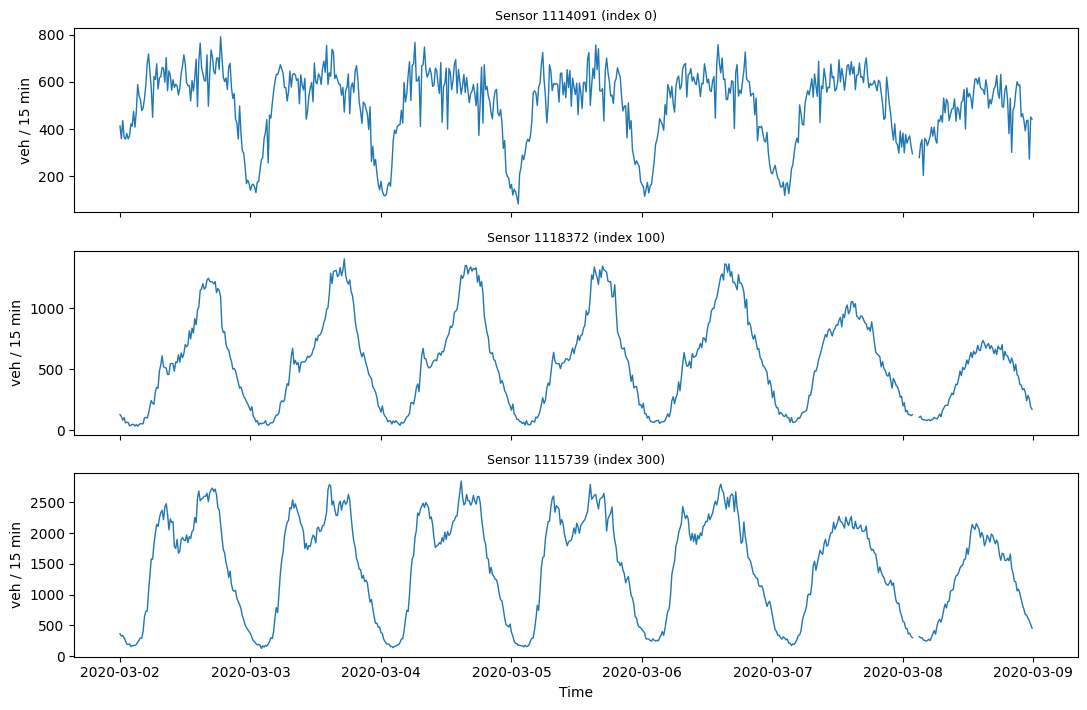

In [ ]:
sensor_indices = [0, 100, 300]         
plot_sensors_one_week(flow, timestamps, sensor_indices, meta_sd["ID"].to_numpy(), week_start="2020-03-02", save_path=f"{FIGURE_DIR}/q3a_sensors_week.pdf");

### Q3(b) Graph construction

In [57]:
print(json.dumps(graph_summary(adjacency), indent=2))
print("Distinct nonzero weights (first 10):", np.unique(adjacency[adjacency != 0])[:10])

{
  "num_nodes": 716,
  "num_nonzero_entries": 18035,
  "num_self_loops": 716,
  "is_symmetric": false,
  "mean_degree": 25.18854748603352,
  "max_degree": 71,
  "min_degree": 1
}
Distinct nonzero weights (first 10): [0.01000184 0.01003287 0.01004842 0.01007959 0.01009521 0.01011084
 0.0101265  0.01014218 0.01015788 0.01018935]


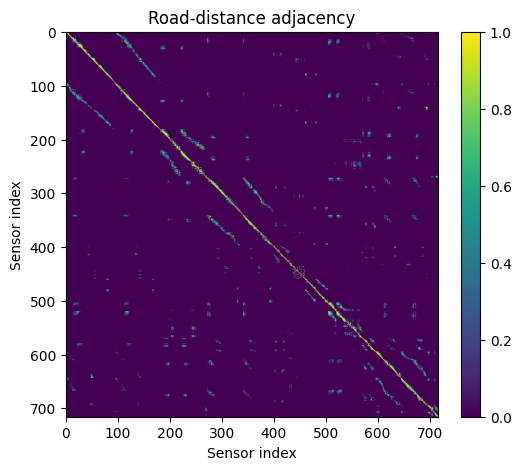

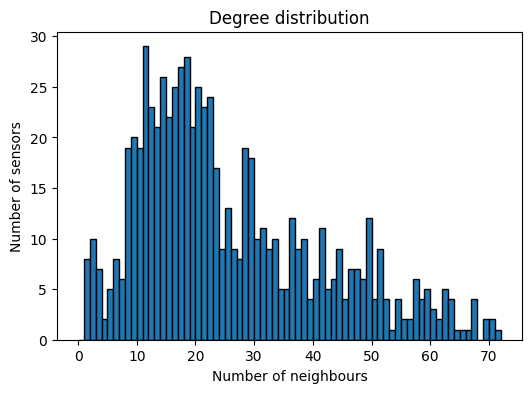

In [58]:
plot_adjacency_heatmap(adjacency, save_path=f"{FIGURE_DIR}/q3b_adj_heatmap.pdf")
plot_degree_histogram(adjacency, save_path=f"{FIGURE_DIR}/q3b_degree_hist.pdf");

### Q3(c) Neighbourhoods

In [59]:
selected_sensor = int(np.argmax((adjacency != 0).sum(axis=1)))   # change if you like
one_hop = k_hop_neighbours(adjacency, selected_sensor, 1)
two_hop = k_hop_neighbours(adjacency, selected_sensor, 2)
print(f"Sensor index {selected_sensor} (ID {meta_sd['ID'][selected_sensor]})")
print("one-hop:", one_hop)
print("two-hop (includes one-hop):", two_hop, f"-> {len(two_hop)} nodes")

Sensor index 342 (ID 1117920)
one-hop: [13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 112, 113, 114, 115, 116, 117, 118, 119, 120, 271, 272, 273, 274, 275, 276, 277, 340, 341, 343, 344, 345, 503, 504, 505, 506, 507, 508, 509, 510, 511, 512, 519, 520, 521, 522, 523, 524, 525, 526, 527, 528, 529, 609, 610, 611, 612, 613, 614, 615, 616, 663, 664, 665, 666, 667, 668, 669, 670, 671, 672]
two-hop (includes one-hop): [10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 107, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 190, 191, 192, 193, 194, 195, 196, 197, 198, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 282, 340, 341, 343, 344, 345, 346, 347, 348, 503, 504, 505, 506, 507, 508, 509, 510, 511, 512, 513, 514, 519, 520, 521, 522, 523, 524, 525, 526, 527, 528, 529, 530, 531, 532, 569, 579, 580, 581, 582, 583, 608, 609, 610, 611, 612, 613, 614, 615, 616, 617, 618, 619, 620, 6

### Q4(a) Splits, normalisation, windows

In [60]:
config = Config(seed=SEED, processed_dir=PROCESSED_DIR, results_dir=RESULTS_DIR,
                checkpoint_dir=CHECKPOINT_DIR)      # edit hyperparameters here; shared by ALL models
loaders, mean, std, adjacency, splits = make_loaders(config)
print(f"train-only mean={mean:.2f}, std={std:.2f}")
for name in ("train", "val", "test"):
    print(name, "steps:", splits[name].raw_flow.shape[0], "| windows:", len(loaders[name].dataset),
          "| range:", splits[name].timestamps[0], "->", splits[name].timestamps[-1])
history, target, mask = next(iter(loaders["train"]))
print("batch shapes:", tuple(history.shape), tuple(target.shape), tuple(mask.shape))

train-only mean=607.29, std=483.57
train steps: 35136 | windows: 35125 | range: 2020-01-01 00:00:00 -> 2020-12-31 23:45:00
val steps: 8640 | windows: 8629 | range: 2021-01-01 00:00:00 -> 2021-03-31 23:45:00
test steps: 26400 | windows: 26389 | range: 2021-04-01 00:00:00 -> 2021-12-31 23:45:00
batch shapes: (64, 8, 716, 1) (64, 4, 716) (64, 4, 716)


### Q4(b) Architecture check

In [61]:
for variant in ("temporal", "fixed", "adaptive", "hybrid"):
    model = build_model(variant, adjacency, INPUT_LENGTH, HORIZON,
                        config.hidden_dim, config.embedding_dim, config.top_k)
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"{variant:9s} params={n_params:>7,d}  output shape={tuple(model(history[:2]).shape)}")

temporal  params= 12,644  output shape=(2, 4, 716)
fixed     params= 13,668  output shape=(2, 4, 716)
adaptive  params= 27,988  output shape=(2, 4, 716)
hybrid    params= 27,989  output shape=(2, 4, 716)


### Q4(c) and Q5: train all four variants
Same encoder, head, splits, seed, optimiser and epoch budget. Slow on CPU: lower `max_epochs` or raise `train_stride` in `Config` (same value for all four). Each run saves to `../results/`, so you can re-run a single cell.

In [62]:
prepared = (loaders, mean, std, adjacency, splits)
results = {}
results["temporal"] = run_experiment("temporal", config, prepared)

[temporal] epoch 01 train_loss(norm)=0.1685 val_MAE=62.320 val_RMSE=98.052
[temporal] epoch 02 train_loss(norm)=0.1224 val_MAE=60.680 val_RMSE=97.580
[temporal] epoch 03 train_loss(norm)=0.1205 val_MAE=59.254 val_RMSE=95.525
[temporal] epoch 04 train_loss(norm)=0.1191 val_MAE=58.827 val_RMSE=94.326
[temporal] epoch 05 train_loss(norm)=0.1182 val_MAE=59.929 val_RMSE=96.979
[temporal] epoch 06 train_loss(norm)=0.1174 val_MAE=58.685 val_RMSE=94.084
[temporal] epoch 07 train_loss(norm)=0.1173 val_MAE=58.972 val_RMSE=94.413
[temporal] epoch 08 train_loss(norm)=0.1170 val_MAE=58.247 val_RMSE=93.828
[temporal] epoch 09 train_loss(norm)=0.1169 val_MAE=57.800 val_RMSE=93.017
[temporal] epoch 10 train_loss(norm)=0.1164 val_MAE=60.319 val_RMSE=94.548
[temporal] epoch 11 train_loss(norm)=0.1162 val_MAE=57.404 val_RMSE=92.606
[temporal] epoch 12 train_loss(norm)=0.1159 val_MAE=58.056 val_RMSE=92.582
[temporal] epoch 13 train_loss(norm)=0.1156 val_MAE=57.272 val_RMSE=92.325
[temporal] epoch 14 train

In [63]:
results["fixed"] = run_experiment("fixed", config, prepared)

[fixed] epoch 01 train_loss(norm)=0.2935 val_MAE=128.181 val_RMSE=193.356
[fixed] epoch 02 train_loss(norm)=0.2552 val_MAE=125.680 val_RMSE=191.095
[fixed] epoch 03 train_loss(norm)=0.2519 val_MAE=124.039 val_RMSE=189.539
[fixed] epoch 04 train_loss(norm)=0.2480 val_MAE=121.259 val_RMSE=186.430
[fixed] epoch 05 train_loss(norm)=0.2399 val_MAE=119.314 val_RMSE=186.708
[fixed] epoch 06 train_loss(norm)=0.2335 val_MAE=115.073 val_RMSE=180.656
[fixed] epoch 07 train_loss(norm)=0.2294 val_MAE=113.330 val_RMSE=178.907
[fixed] epoch 08 train_loss(norm)=0.2257 val_MAE=112.201 val_RMSE=179.017
[fixed] epoch 09 train_loss(norm)=0.2230 val_MAE=110.141 val_RMSE=175.948
[fixed] epoch 10 train_loss(norm)=0.2203 val_MAE=109.522 val_RMSE=175.624
[fixed] epoch 11 train_loss(norm)=0.2188 val_MAE=108.428 val_RMSE=174.394
[fixed] epoch 12 train_loss(norm)=0.2172 val_MAE=108.043 val_RMSE=175.337
[fixed] epoch 13 train_loss(norm)=0.2159 val_MAE=107.036 val_RMSE=174.305
[fixed] epoch 14 train_loss(norm)=0.21

In [64]:
results["adaptive"] = run_experiment("adaptive", config, prepared)

[adaptive] epoch 01 train_loss(norm)=0.3233 val_MAE=112.185 val_RMSE=172.770
[adaptive] epoch 02 train_loss(norm)=0.2005 val_MAE=96.746 val_RMSE=153.718
[adaptive] epoch 03 train_loss(norm)=0.1815 val_MAE=91.112 val_RMSE=147.437
[adaptive] epoch 04 train_loss(norm)=0.1731 val_MAE=87.816 val_RMSE=141.770
[adaptive] epoch 05 train_loss(norm)=0.1669 val_MAE=86.684 val_RMSE=140.727
[adaptive] epoch 06 train_loss(norm)=0.1625 val_MAE=85.678 val_RMSE=138.721
[adaptive] epoch 07 train_loss(norm)=0.1594 val_MAE=82.517 val_RMSE=135.884
[adaptive] epoch 08 train_loss(norm)=0.1568 val_MAE=81.692 val_RMSE=135.205
[adaptive] epoch 09 train_loss(norm)=0.1546 val_MAE=82.718 val_RMSE=136.284
[adaptive] epoch 10 train_loss(norm)=0.1531 val_MAE=80.407 val_RMSE=133.244
[adaptive] epoch 11 train_loss(norm)=0.1518 val_MAE=80.891 val_RMSE=132.916
[adaptive] epoch 12 train_loss(norm)=0.1500 val_MAE=79.051 val_RMSE=132.194
[adaptive] epoch 13 train_loss(norm)=0.1492 val_MAE=79.440 val_RMSE=131.443
[adaptive] 

In [65]:
results["hybrid"] = run_experiment("hybrid", config, prepared)
print("learned alpha:", results["hybrid"].get("final_alpha"))

[hybrid] epoch 01 train_loss(norm)=0.2707 val_MAE=98.488 val_RMSE=151.889
[hybrid] epoch 02 train_loss(norm)=0.1820 val_MAE=90.472 val_RMSE=140.936
[hybrid] epoch 03 train_loss(norm)=0.1682 val_MAE=86.037 val_RMSE=135.381
[hybrid] epoch 04 train_loss(norm)=0.1585 val_MAE=79.533 val_RMSE=126.932
[hybrid] epoch 05 train_loss(norm)=0.1520 val_MAE=78.381 val_RMSE=125.997
[hybrid] epoch 06 train_loss(norm)=0.1471 val_MAE=75.499 val_RMSE=122.154
[hybrid] epoch 07 train_loss(norm)=0.1426 val_MAE=74.554 val_RMSE=121.894
[hybrid] epoch 08 train_loss(norm)=0.1397 val_MAE=71.529 val_RMSE=118.345
[hybrid] epoch 09 train_loss(norm)=0.1375 val_MAE=70.902 val_RMSE=116.145
[hybrid] epoch 10 train_loss(norm)=0.1356 val_MAE=69.588 val_RMSE=114.940
[hybrid] epoch 11 train_loss(norm)=0.1340 val_MAE=70.826 val_RMSE=116.967
[hybrid] epoch 12 train_loss(norm)=0.1324 val_MAE=68.974 val_RMSE=113.938
[hybrid] epoch 13 train_loss(norm)=0.1317 val_MAE=67.906 val_RMSE=113.467
[hybrid] epoch 14 train_loss(norm)=0.1

### Q5(b) Learned adjacency

row sums (should be 1): [1.         1.         0.99999994] | nonzeros per row: [20 20 20]


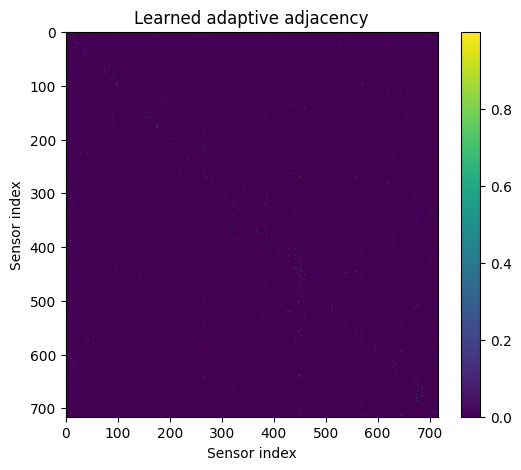

In [66]:
learned = np.load(f"{RESULTS_DIR}/adaptive_learned_adjacency.npy")
plot_learned_adjacency(learned, save_path=f"{FIGURE_DIR}/q5b_adaptive_adj.pdf")
print("row sums (should be 1):", learned.sum(axis=1)[:3], "| nonzeros per row:", (learned > 0).sum(axis=1)[:3])

### Q6(a) Results table and prediction plots

In [67]:
table = results_table(RESULTS_DIR)
print(table.to_string(index=False))
print(table.to_latex(index=False))

        Model Adjacency  Val MAE  Val RMSE  Test MAE  Test RMSE  Training time (s)  Epochs
Temporal-only      None    56.07     90.13     64.66     101.63              636.5      30
        STGNN     Fixed    99.59    165.30    112.82     182.47              708.9      30
        STGNN  Adaptive    70.73    120.37     88.38     139.00              775.2      30
        STGNN    Hybrid    64.09    108.78     78.43     122.74              788.3      30
\begin{tabular}{llrrrrrr}
\toprule
Model & Adjacency & Val MAE & Val RMSE & Test MAE & Test RMSE & Training time (s) & Epochs \\
\midrule
Temporal-only & None & 56.070000 & 90.130000 & 64.660000 & 101.630000 & 636.500000 & 30 \\
STGNN & Fixed & 99.590000 & 165.300000 & 112.820000 & 182.470000 & 708.900000 & 30 \\
STGNN & Adaptive & 70.730000 & 120.370000 & 88.380000 & 139.000000 & 775.200000 & 30 \\
STGNN & Hybrid & 64.090000 & 108.780000 & 78.430000 & 122.740000 & 788.300000 & 30 \\
\bottomrule
\end{tabular}



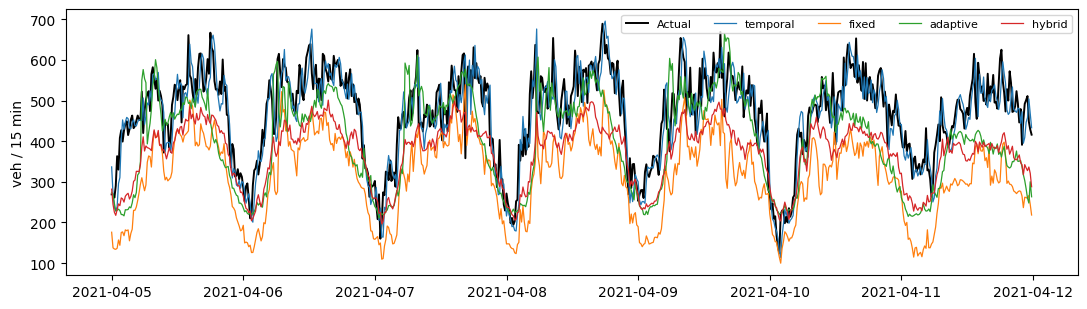

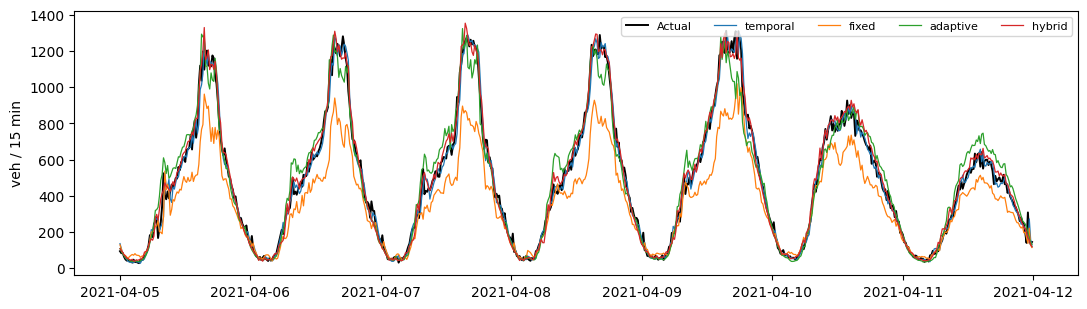

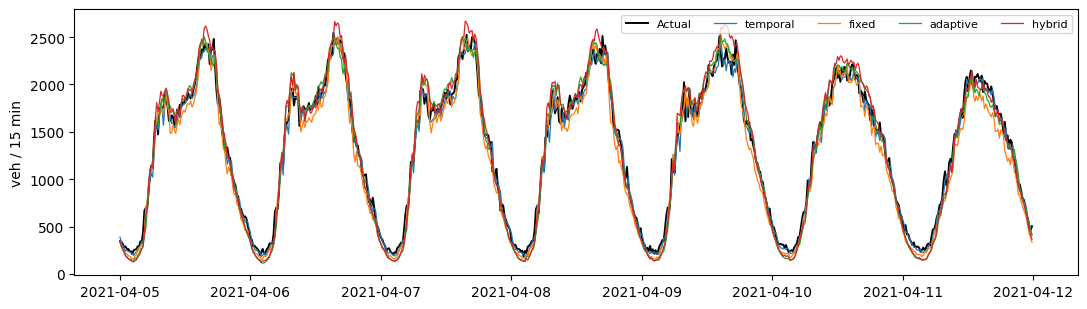

In [68]:
test_timestamps = splits["test"].timestamps
for position, sensor in enumerate(config.prediction_sensors):
    plot_pred_vs_actual(RESULTS_DIR, ["temporal", "fixed", "adaptive", "hybrid"],
                        sensor_position=position, horizon_step=0, test_start="2021-04-05",
                        timestamps_test=test_timestamps,
                        save_path=f"{FIGURE_DIR}/q6a_pred_vs_actual_sensor{sensor}.pdf")

### Q6(b) Graph structure analysis

In [69]:
for k in (10, 20):
    print(f"top-{k} learned edges present in road graph: {edge_overlap_with_fixed(learned, adjacency, k=k):.1%}")

top-10 learned edges present in road graph: 5.3%
top-20 learned edges present in road graph: 4.3%


median distance: learned 21.3 km vs road-graph 2.4 km
learned edges farther than 10 km: 78.8%


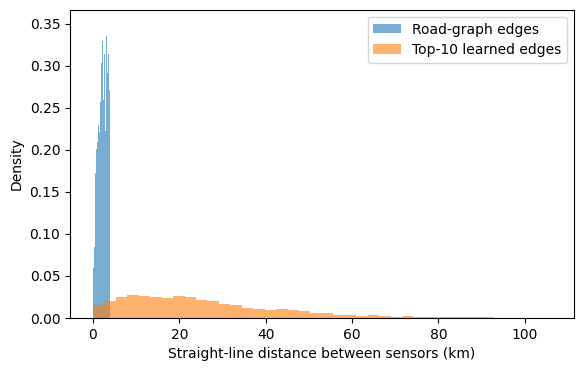

In [70]:
fig, learned_km, road_km = plot_edge_distance_comparison(
    learned, adjacency, meta_sd, k=10, save_path=f"{FIGURE_DIR}/q6b_edge_distances.pdf")
print(f"median distance: learned {np.median(learned_km):.1f} km vs road-graph {np.median(road_km):.1f} km")
print(f"learned edges farther than 10 km: {(learned_km > 10).mean():.1%}")

### Q7 Reproducibility record

In [71]:
print("Python:", platform.python_version(), "| torch:", torch.__version__, "| numpy:", np.__version__)
print("Platform:", platform.platform(), "| CPU:", platform.processor(), "| cores:", os.cpu_count())
print("CUDA:", torch.cuda.is_available(), "| MPS:", torch.backends.mps.is_available(), "| used:", pick_device())
print("seed:", config.seed, "| hidden_dim:", config.hidden_dim, "| lr:", config.learning_rate,
      "| batch:", config.batch_size, "| max_epochs:", config.max_epochs, "| patience:", config.patience)
for variant, result in results.items():
    print(variant, f"train {result['training_seconds']:.0f}s over {result['epochs_run']} epochs "
          f"({result['seconds_per_epoch']:.1f}s/epoch), best epoch {result['best_epoch']}")

Python: 3.11.13 | torch: 2.8.0 | numpy: 2.2.6
Platform: macOS-26.6.2-arm64-arm-64bit | CPU: arm | cores: 10
CUDA: False | MPS: True | used: mps
seed: 42 | hidden_dim: 32 | lr: 0.001 | batch: 64 | max_epochs: 30 | patience: 5
temporal train 636s over 30 epochs (21.2s/epoch), best epoch 30
fixed train 709s over 30 epochs (23.6s/epoch), best epoch 30
adaptive train 775s over 30 epochs (25.8s/epoch), best epoch 30
hybrid train 788s over 30 epochs (26.3s/epoch), best epoch 27


nonzeros per row (mean): 20.0
row max: mean 0.345 | median 0.3
self-weight (diagonal) mean: 0.0193


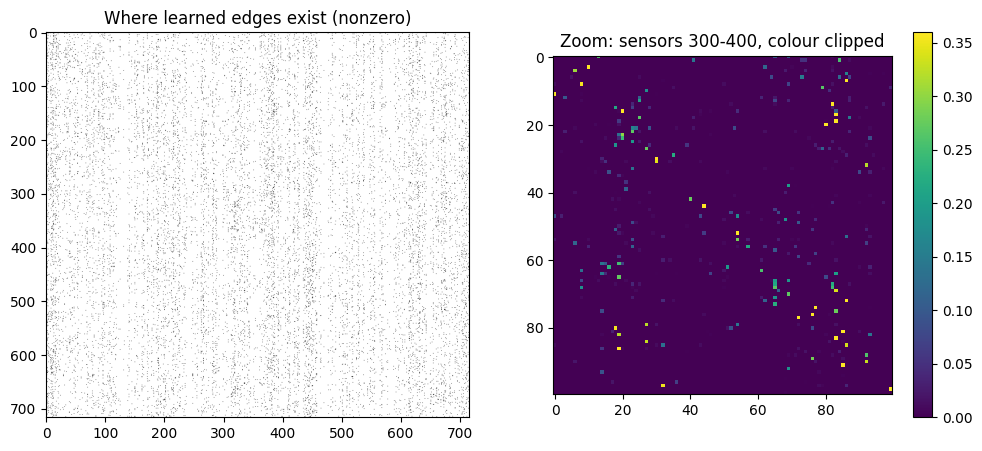

In [73]:
print("nonzeros per row (mean):", (learned > 0).sum(axis=1).mean())
print("row max: mean", learned.max(axis=1).mean().round(3),
      "| median", np.median(learned.max(axis=1)).round(3))
print("self-weight (diagonal) mean:", np.diag(learned).mean().round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(learned > 0, cmap="gray_r", aspect="auto")
axes[0].set_title("Where learned edges exist (nonzero)")
block = learned[300:400, 300:400]
image = axes[1].imshow(block, cmap="viridis", vmax=np.percentile(block[block > 0], 95))
axes[1].set_title("Zoom: sensors 300-400, colour clipped")
fig.colorbar(image, ax=axes[1])
fig.savefig(f"{FIGURE_DIR}/q5b_adaptive_adj.pdf", bbox_inches="tight")

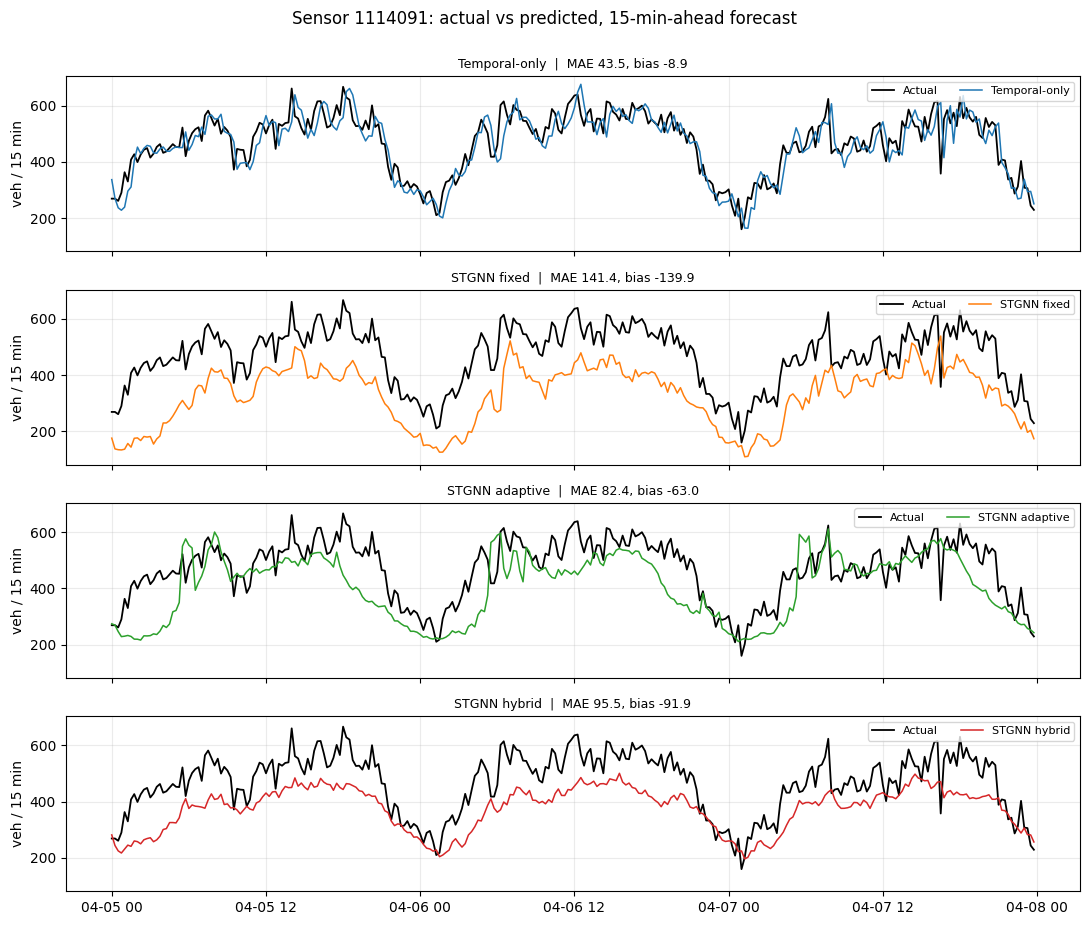

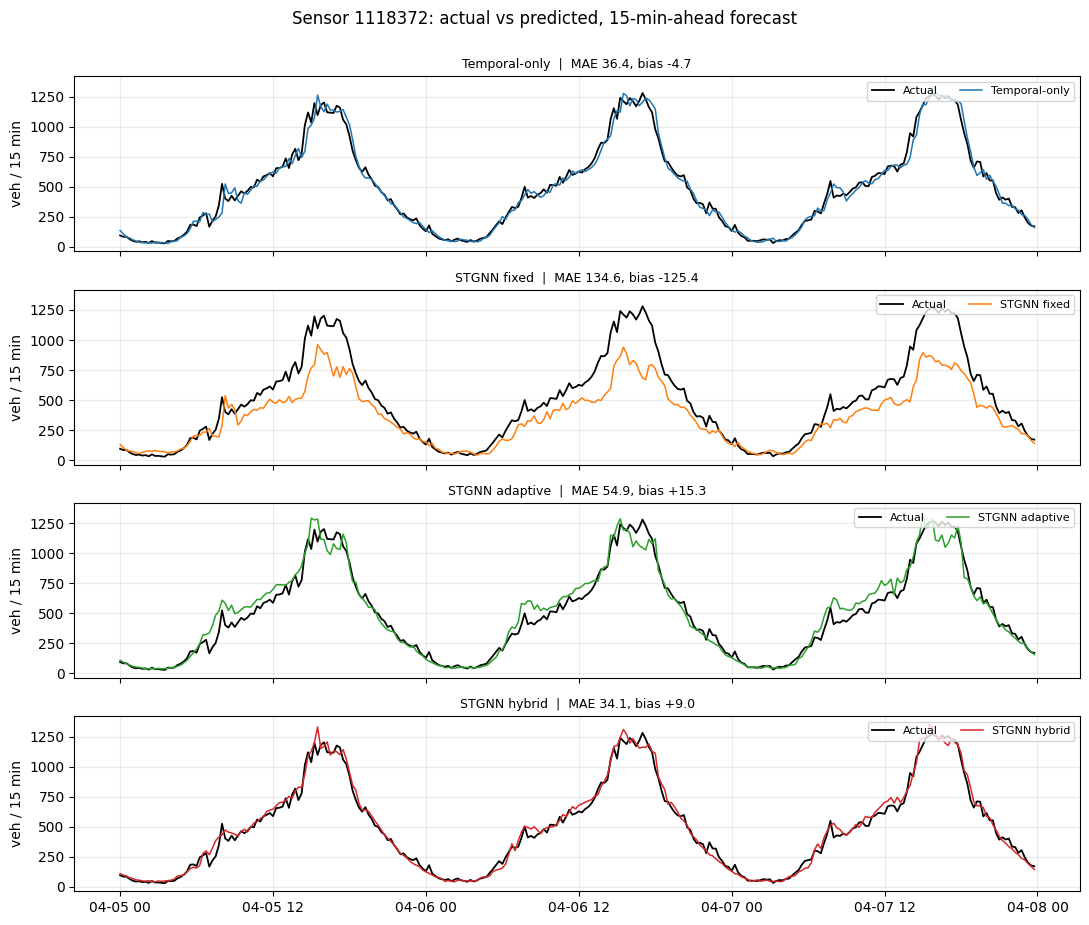

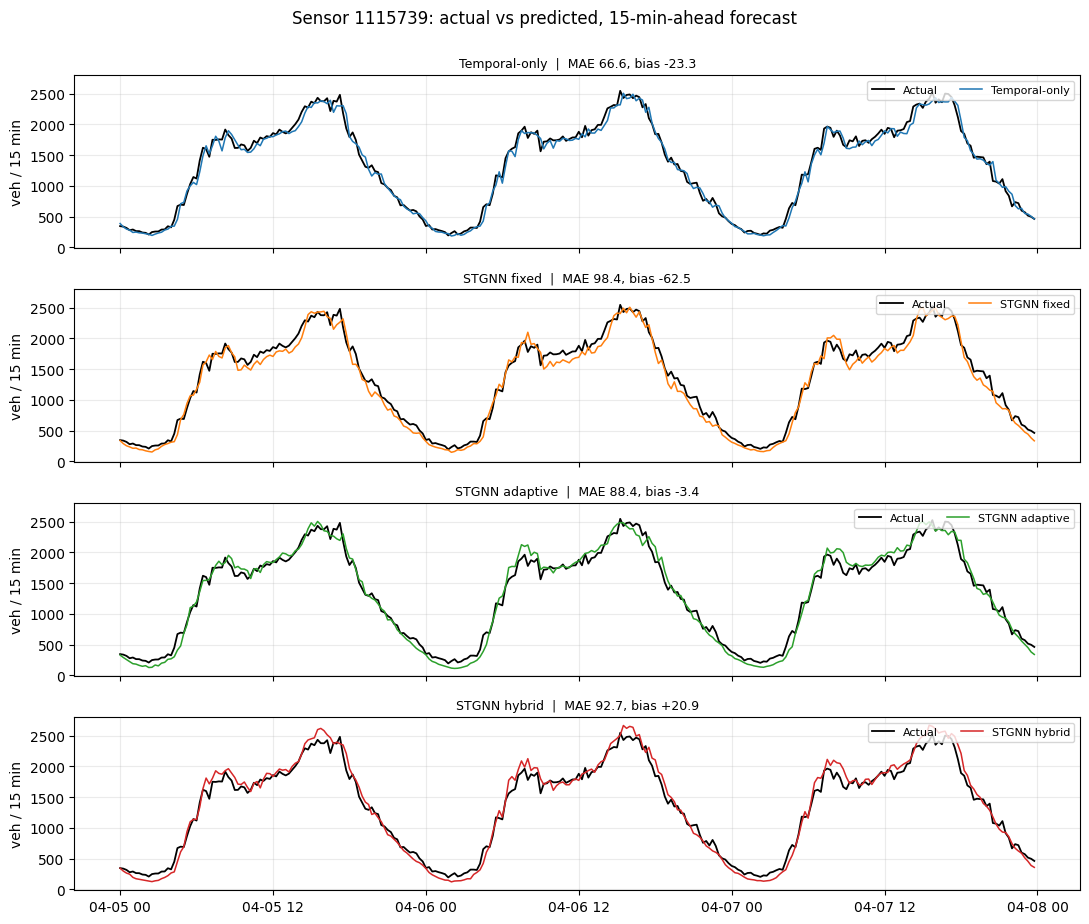

In [74]:
VARIANT_LABELS = {"temporal": "Temporal-only", "fixed": "STGNN fixed",
                  "adaptive": "STGNN adaptive", "hybrid": "STGNN hybrid"}


def plot_pred_vs_actual_panels(results_dir, variants, sensor_position, sensor_id,
                               timestamps_test, horizon_step=0, start="2021-04-05",
                               num_days=3, save_path=None):
    """One panel per model: black = actual, coloured = that model's prediction.

    num_days controls the zoom (3 days is much clearer than a full week).
    Window i forecasts test-split time step (i + INPUT_LENGTH + horizon_step).
    """
    saved = {v: np.load(Path(results_dir) / f"{v}_test_predictions.npz") for v in variants}
    actual_full = saved[variants[0]]["target"][:, horizon_step, sensor_position]
    offset = INPUT_LENGTH + horizon_step
    time_axis = timestamps_test[offset: offset + len(actual_full)]

    first = int(np.searchsorted(time_axis, pd.Timestamp(start)))
    window = slice(first, first + num_days * STEPS_PER_DAY)
    actual = actual_full[window]
    times = time_axis[window]

    fig, axes = plt.subplots(len(variants), 1, figsize=(11, 2.3 * len(variants)),
                             sharex=True, sharey=True)
    colours = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    for axis, variant, colour in zip(axes, variants, colours):
        predicted = saved[variant]["prediction"][:, horizon_step, sensor_position][window]
        mae = np.abs(predicted - actual).mean()
        bias = (predicted - actual).mean()
        axis.plot(times, actual, color="black", linewidth=1.3, label="Actual")
        axis.plot(times, predicted, color=colour, linewidth=1.1, label=VARIANT_LABELS[variant])
        axis.set_ylabel("veh / 15 min")
        axis.set_title(f"{VARIANT_LABELS[variant]}  |  MAE {mae:.1f}, bias {bias:+.1f}", fontsize=9)
        axis.legend(loc="upper right", fontsize=8, ncol=2)
        axis.grid(alpha=0.25)
    horizon_minutes = 15 * (horizon_step + 1)
    fig.suptitle(f"Sensor {sensor_id}: actual vs predicted, {horizon_minutes}-min-ahead forecast", y=1.0)
    fig.tight_layout()
    return _finish(fig, save_path)


test_timestamps = splits["test"].timestamps
for position, sensor in enumerate(config.prediction_sensors):
    plot_pred_vs_actual_panels(
        RESULTS_DIR, ["temporal", "fixed", "adaptive", "hybrid"],
        sensor_position=position, sensor_id=meta_sd["ID"][sensor],
        timestamps_test=test_timestamps, horizon_step=0, start="2021-04-05", num_days=3,
        save_path=f"{FIGURE_DIR}/q6a_panels_sensor{sensor}.pdf")

In [75]:
def baseline_metrics(loader, predict):
    abs_sum = sq_sum = count = 0.0
    for history, target, mask in loader:
        error = (predict(history) - target) * std * mask      # original units
        abs_sum += error.abs().sum().item()
        sq_sum += (error ** 2).sum().item()
        count += mask.sum().item()
    return abs_sum / count, (sq_sum / count) ** 0.5

predict_train_mean = lambda h: torch.zeros(h.shape[0], 4, h.shape[2])
predict_last_value = lambda h: h[:, -1, :, 0].unsqueeze(1).repeat(1, 4, 1)
print("train-mean baseline (MAE, RMSE):", baseline_metrics(loaders["val"], predict_train_mean))
print("persistence baseline (MAE, RMSE):", baseline_metrics(loaders["val"], predict_last_value))

for mode in ("sym", "row"):
    normalised = normalise_adjacency(adjacency, mode)
    print(mode, "finite:", np.isfinite(normalised).all(), "| row sums min/max:",
          normalised.sum(1).min().round(3), normalised.sum(1).max().round(3))
print("raw adjacency range:", adjacency.min(), adjacency.max())

train-mean baseline (MAE, RMSE): (412.12159614947166, 499.90231895687316)
persistence baseline (MAE, RMSE): (81.22153135361306, 125.36271574239179)
sym finite: True | row sums min/max: 0.787 1.407
row finite: True | row sums min/max: 1.0 1.0
raw adjacency range: 0.0 1.0


In [76]:
print("train mean/std:", round(mean, 1), round(std, 1))
for name in ("train", "val", "test"):
    values = splits[name].raw_flow
    print(name, "mean:", round(float(np.nanmean(values)), 1),
          "| zero fraction:", round(float(np.nanmean(values == 0)), 4))

train mean/std: 607.3 483.6
train mean: 607.3 | zero fraction: 0.0015
val mean: 635.3 | zero fraction: 0.0017
test mean: 720.8 | zero fraction: 0.0012


[fixed] epoch 01 train_loss(norm)=0.1623 val_MAE=59.644 val_RMSE=96.446
[fixed] epoch 02 train_loss(norm)=0.1197 val_MAE=58.209 val_RMSE=94.741
[fixed] epoch 03 train_loss(norm)=0.1179 val_MAE=57.781 val_RMSE=93.670
[fixed] epoch 04 train_loss(norm)=0.1165 val_MAE=57.876 val_RMSE=92.956
[fixed] epoch 05 train_loss(norm)=0.1150 val_MAE=57.921 val_RMSE=93.165
[fixed] epoch 06 train_loss(norm)=0.1139 val_MAE=55.773 val_RMSE=90.492
[fixed] epoch 07 train_loss(norm)=0.1130 val_MAE=57.727 val_RMSE=92.525
[fixed] epoch 08 train_loss(norm)=0.1125 val_MAE=56.472 val_RMSE=90.723
[fixed] epoch 09 train_loss(norm)=0.1122 val_MAE=55.187 val_RMSE=89.272
[fixed] epoch 10 train_loss(norm)=0.1116 val_MAE=55.609 val_RMSE=89.151
[fixed] epoch 11 train_loss(norm)=0.1111 val_MAE=55.370 val_RMSE=89.264
[fixed] epoch 12 train_loss(norm)=0.1104 val_MAE=54.251 val_RMSE=87.869
[fixed] epoch 13 train_loss(norm)=0.1102 val_MAE=54.123 val_RMSE=87.860
[fixed] epoch 14 train_loss(norm)=0.1098 val_MAE=53.973 val_RMSE

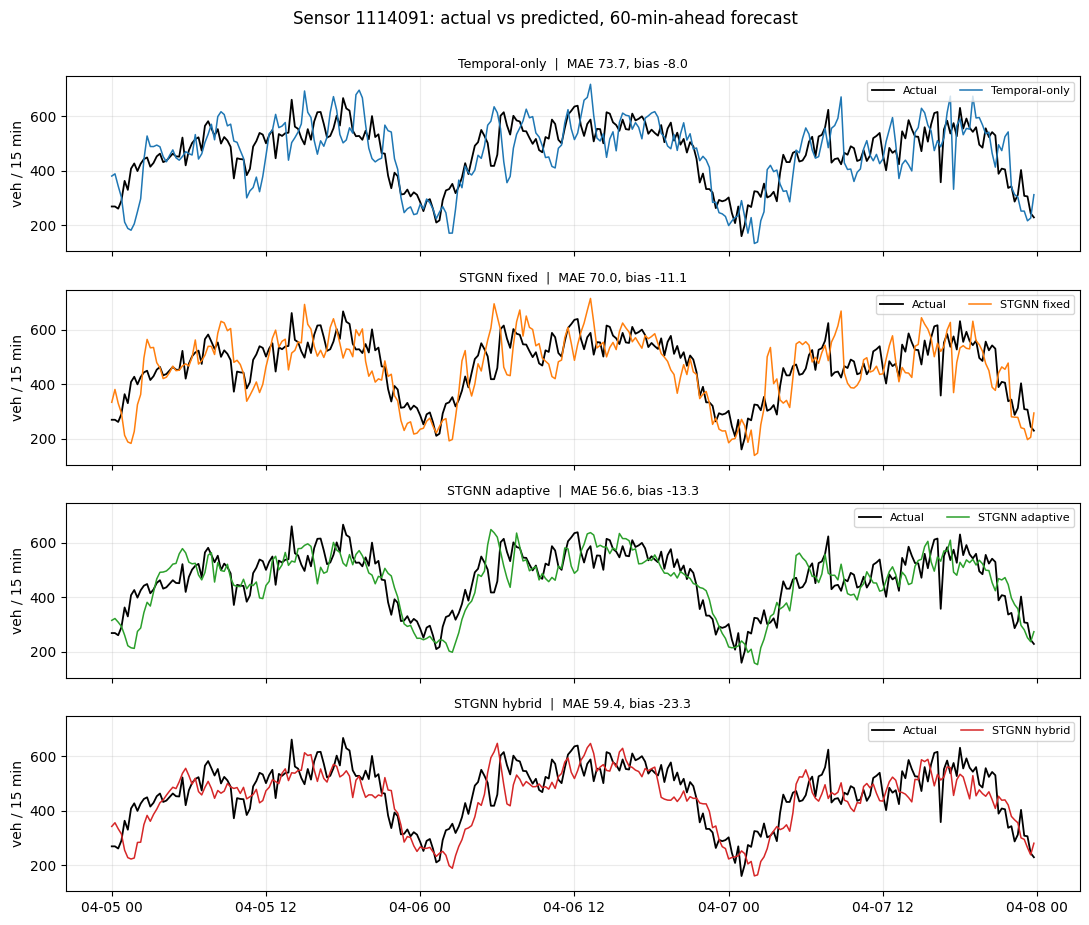

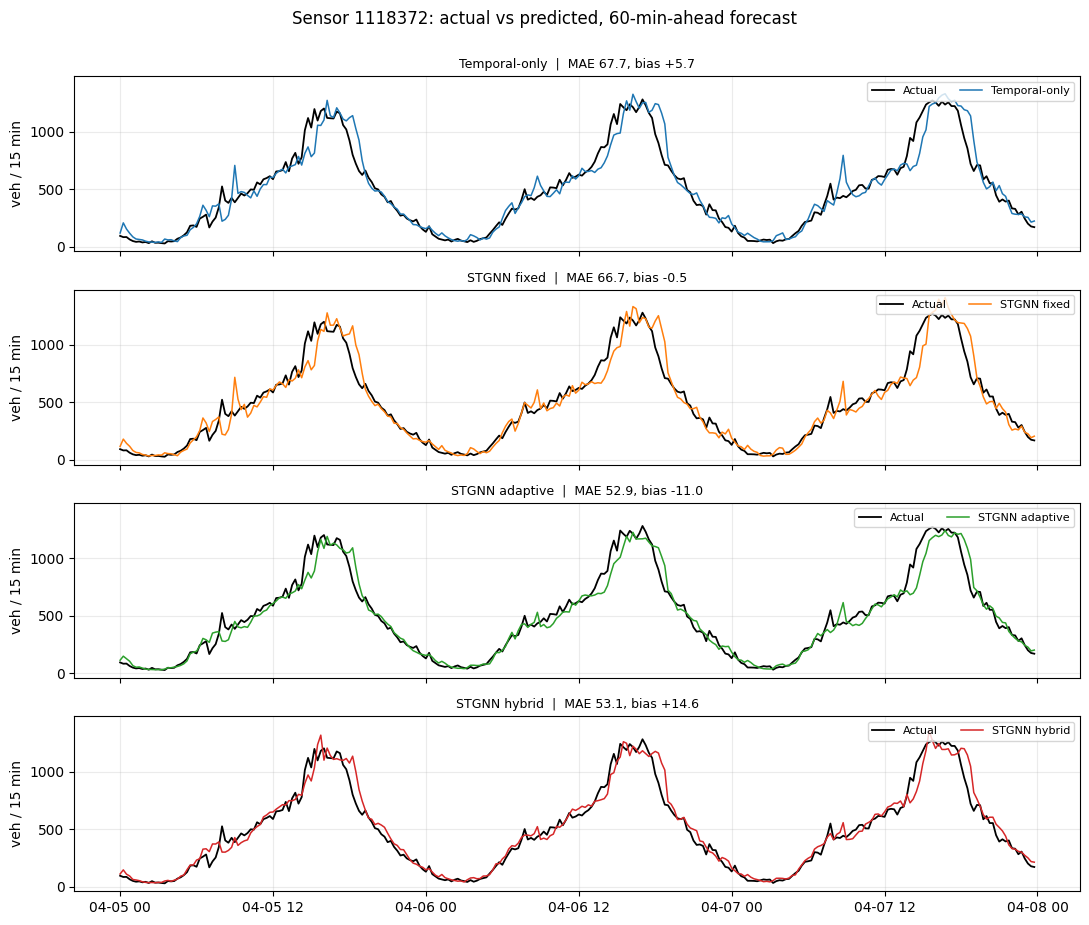

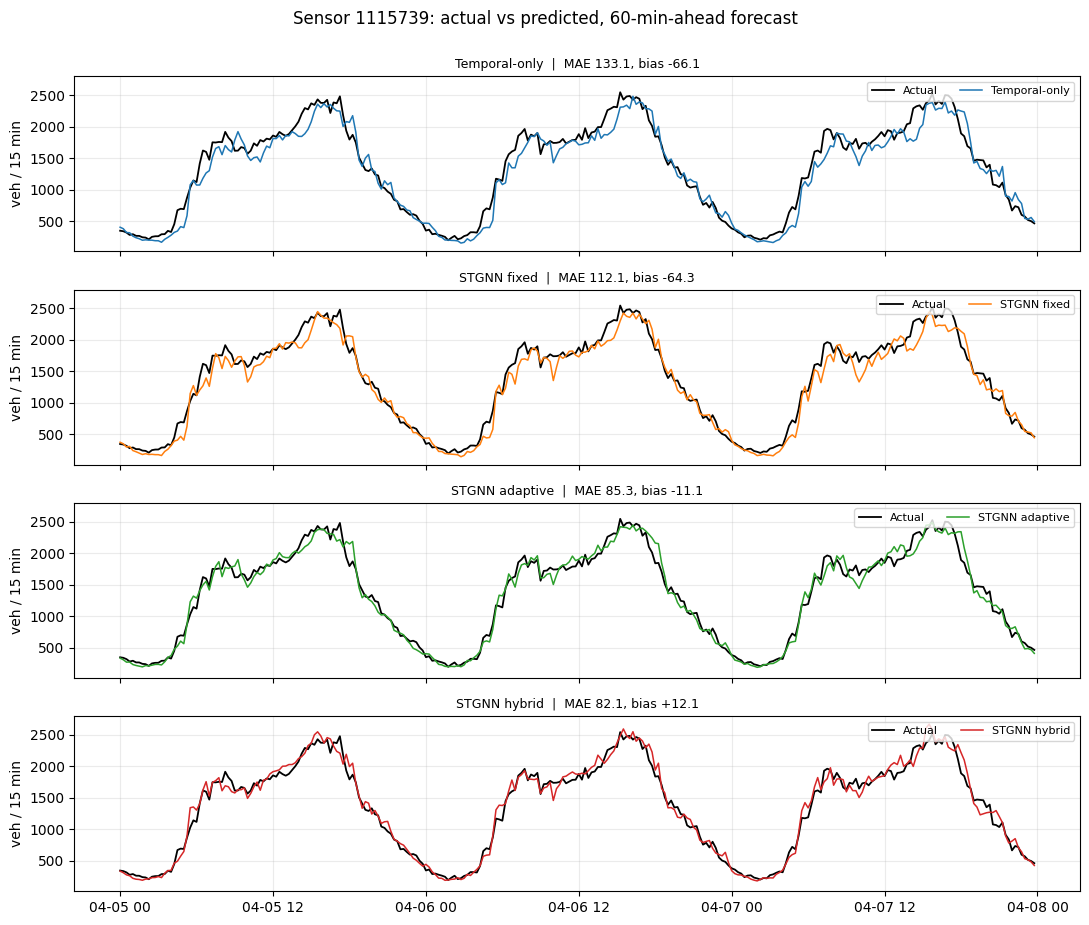

In [77]:
import shutil
from dataclasses import replace

RESIDUAL_DIR = "../results_residual"
RESIDUAL_CHECKPOINT_DIR = "../checkpoints_residual"
Path(RESIDUAL_DIR).mkdir(parents=True, exist_ok=True)


class ResidualGraphConv(GraphConv):
    """Graph convolution that keeps each sensor's own features: ReLU(A_hat Z W) + Z."""

    def forward(self, node_features, adjacency):
        return super().forward(node_features, adjacency) + node_features


residual_config = replace(config, results_dir=RESIDUAL_DIR, checkpoint_dir=RESIDUAL_CHECKPOINT_DIR)
residual_results = {}

original_graph_conv = GraphConv        
GraphConv = ResidualGraphConv
try:
    for variant in ("fixed", "adaptive", "hybrid"):
        saved_file = Path(RESIDUAL_DIR) / f"{variant}.json"
        if saved_file.exists():        
            residual_results[variant] = json.loads(saved_file.read_text())
            print(f"[{variant}] found saved result, skipping training")
        else:
            residual_results[variant] = run_experiment(variant, residual_config, prepared)
finally:
    GraphConv = original_graph_conv    

for suffix in (".json", "_test_predictions.npz"):
    shutil.copy(Path(RESULTS_DIR) / f"temporal{suffix}", Path(RESIDUAL_DIR) / f"temporal{suffix}")


test_mean_flow = float(np.nanmean(splits["test"].raw_flow))
adjacency_label = {"temporal": "None", "fixed": "Fixed", "adaptive": "Adaptive", "hybrid": "Hybrid"}
comparison_rows = []
for variant in ("temporal", "fixed", "adaptive", "hybrid"):
    for layer_label, directory in (("as specified", RESULTS_DIR), ("with skip", RESIDUAL_DIR)):
        if variant == "temporal" and layer_label == "with skip":
            continue                                   
        result = json.loads((Path(directory) / f"{variant}.json").read_text())
        comparison_rows.append({
            "Model": "Temporal-only" if variant == "temporal" else "STGNN",
            "Adjacency": adjacency_label[variant],
            "Graph layer": "-" if variant == "temporal" else layer_label,
            "Val MAE": round(result["val"]["mae"], 2),
            "Val RMSE": round(result["val"]["rmse"], 2),
            "Test MAE": round(result["test"]["mae"], 2),
            "Test RMSE": round(result["test"]["rmse"], 2),
            "Test MAE (% of mean flow)": round(100 * result["test"]["mae"] / test_mean_flow, 1),
            "Train time (s)": round(result["training_seconds"], 1),
            "Best epoch / run": f"{result['best_epoch']}/{result['epochs_run']}",
        })
comparison_table = pd.DataFrame(comparison_rows)
print(comparison_table.to_string(index=False))
print(comparison_table.to_latex(index=False))

hybrid_alpha_spec = json.loads((Path(RESULTS_DIR) / "hybrid.json").read_text()).get("final_alpha")
hybrid_alpha_skip = residual_results["hybrid"].get("final_alpha")
print(f"\nlearned alpha (hybrid): as specified = {hybrid_alpha_spec}, with skip = {hybrid_alpha_skip}")


for position, sensor in enumerate(config.prediction_sensors):
    plot_pred_vs_actual_panels(
        RESIDUAL_DIR, ["temporal", "fixed", "adaptive", "hybrid"],
        sensor_position=position, sensor_id=meta_sd["ID"][sensor],
        timestamps_test=splits["test"].timestamps, horizon_step=3, start="2021-04-05", num_days=3,
        save_path=f"{FIGURE_DIR}/q6a_panels_residual_sensor{sensor}.pdf")

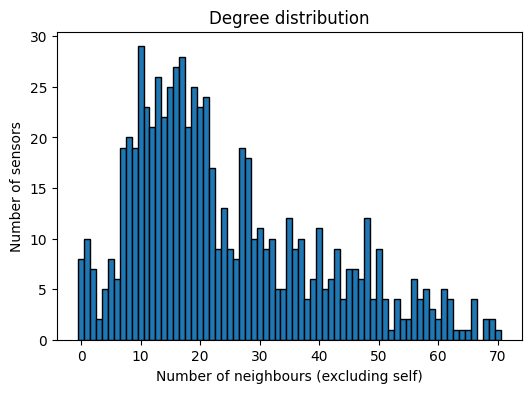

In [81]:
def plot_adjacency_heatmap(adjacency, title="Road-distance adjacency", save_path=None):
    fig, axis = plt.subplots(figsize=(6, 5))
    image = axis.imshow(adjacency, cmap="plasma", aspect="auto")
    axis.set_title(title)
    axis.set_xlabel("Sensor index")
    axis.set_ylabel("Sensor index")
    fig.colorbar(image, ax=axis)
    return _finish(fig, save_path)

def plot_degree_histogram(adjacency, save_path=None):
    nonzero = adjacency != 0
    self_loops = np.diag(nonzero).astype(int)
    degrees = nonzero.sum(axis=1) - self_loops

    fig, axis = plt.subplots(figsize=(6, 4))
    bins = np.arange(degrees.max() + 2) - 0.5
    axis.hist(degrees, bins=bins, edgecolor="black")
    axis.set_xlabel("Number of neighbours (excluding self)")
    axis.set_ylabel("Number of sensors")
    axis.set_title("Degree distribution")
    return _finish(fig, save_path)

plot_degree_histogram(adjacency, save_path=f"{FIGURE_DIR}/q3b_degree_hist.pdf");